In [ ]:
!nvidia-smi

Wed Oct 28 20:48:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -U "diffusers[training]" datasets accelerate

INFO: pip is looking at multiple versions of tensorboard to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 31.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 74.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 125.0 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.33.6
    Uninstalling protobuf-6.33.6:
      Successfully uninstalled protobuf-6.33.6
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.21.0
    Uninstalling tensorboard-2.21.0:
      Successfully uninstalled tensorboard-2.21.0
  Attempting uninstall: diffusers
    Found existing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from datasets import load_dataset
ds = load_dataset("huggan/smithsonian_butterflies_subset", split="train")
print(ds)

README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['image_url', 'image_alt', 'id', 'name', 'scientific_name', 'gender', 'taxonomy', 'region', 'locality', 'date', 'usnm_no', 'guid', 'edan_url', 'source', 'stage', 'image', 'image_hash', 'sim_score'],
    num_rows: 1000
})


In [2]:
from datasets import load_dataset
ds = load_dataset("Ansh007/Jellyfish-Image-Dataset", split="train")
print(ds)

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

Train-Test-Valid.zip: reconstructing file:   0%|          |  0.00B / 13.9MB            

Train-Test-Valid.zip: downloading bytes:           |  0.00B            

jellyfish.zip: reconstructing file:   0%|          |  0.00B / 12.7MB            

jellyfish.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1879 [00:00<?, ? examples/s]

Dataset({
    features: ['image'],
    num_rows: 1879
})


In [6]:
import torch, torch.nn.functional as F
from torchvision import transforms
from diffusers import UNet2DModel, DDPMScheduler
from diffusers.optimization import get_cosine_schedule_with_warmup

IMAGE_SIZE = 64      # resolution of the generated images
BATCH_SIZE = 16
EPOCHS = 25           # test run first; change to 100 for the real run
LR = 1e-4
OUT = "/content/drive/MyDrive/jungle-unet-jellyfish"   # saved to your Drive

device = "cuda"

preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

def transform(examples):
    return {"images": [preprocess(img.convert("RGB")) for img in examples["image"]]}

ds.set_transform(transform)
loader = torch.utils.data.DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)

model = UNet2DModel(
    sample_size=IMAGE_SIZE, in_channels=3, out_channels=3, layers_per_block=2,
    block_out_channels=(128, 128, 256, 256),
    down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

noise_scheduler = DDPMScheduler(num_train_timesteps=1000)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=200, num_training_steps=len(loader) * EPOCHS)
print("ready:", len(loader), "steps per epoch")

ready: 118 steps per epoch


epoch 1/25  loss 0.3366  time 45s
epoch 2/25  loss 0.0530  time 89s
epoch 3/25  loss 0.0361  time 134s
epoch 4/25  loss 0.0313  time 178s
epoch 5/25  loss 0.0285  time 223s
epoch 6/25  loss 0.0281  time 267s
epoch 7/25  loss 0.0244  time 312s
epoch 8/25  loss 0.0269  time 356s
epoch 9/25  loss 0.0269  time 400s
epoch 10/25  loss 0.0222  time 445s
epoch 11/25  loss 0.0223  time 489s
epoch 12/25  loss 0.0218  time 534s
epoch 13/25  loss 0.0231  time 579s
epoch 14/25  loss 0.0203  time 623s
epoch 15/25  loss 0.0214  time 668s
epoch 16/25  loss 0.0182  time 712s
epoch 17/25  loss 0.0221  time 756s
epoch 18/25  loss 0.0209  time 801s
epoch 19/25  loss 0.0189  time 845s
epoch 20/25  loss 0.0207  time 890s
epoch 21/25  loss 0.0185  time 935s
epoch 22/25  loss 0.0224  time 979s
epoch 23/25  loss 0.0172  time 1024s
epoch 24/25  loss 0.0211  time 1068s
epoch 25/25  loss 0.0179  time 1113s


  0%|          | 0/1000 [00:00<?, ?it/s]

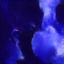

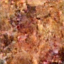

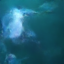

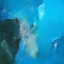

saved to /content/drive/MyDrive/jungle-unet-jellyfish


In [7]:
import time, os
from diffusers import DDPMPipeline
from IPython.display import display

os.makedirs(OUT, exist_ok=True)
scaler = torch.amp.GradScaler("cuda")
model.train()
start = time.time()

for epoch in range(EPOCHS):
    total = 0
    for batch in loader:
        clean = batch["images"].to(device)
        noise = torch.randn_like(clean)
        t = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                          (clean.shape[0],), device=device).long()
        noisy = noise_scheduler.add_noise(clean, noise, t)

        with torch.autocast("cuda", dtype=torch.float16):
            pred = model(noisy, t, return_dict=False)[0]
            loss = F.mse_loss(pred.float(), noise)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        lr_scheduler.step()
        total += loss.item()

    print(f"epoch {epoch+1}/{EPOCHS}  loss {total/len(loader):.4f}  time {time.time()-start:.0f}s")

    if (epoch + 1) % 10 == 0:
        model.save_pretrained(OUT)

    if (epoch + 1) % 25 == 0:
        model.eval()
        pipe = DDPMPipeline(unet=model, scheduler=noise_scheduler).to("cuda")
        for im in pipe(batch_size=4, generator=torch.manual_seed(0)).images:
            display(im)
        model.train()

model.save_pretrained(OUT)
print("saved to", OUT)

In [8]:
import os
from diffusers import DDPMPipeline

model.eval()
pipeline = DDPMPipeline(unet=model, scheduler=noise_scheduler).to("cuda")
os.makedirs("images", exist_ok=True)

n = 0
for seed in range(2):
    batch = pipeline(batch_size=25, generator=torch.manual_seed(100 + seed)).images
    for img in batch:
        img.save(f"images/jellyfish_{n:02d}.png")
        n += 1
print("saved", n, "images")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

saved 50 images


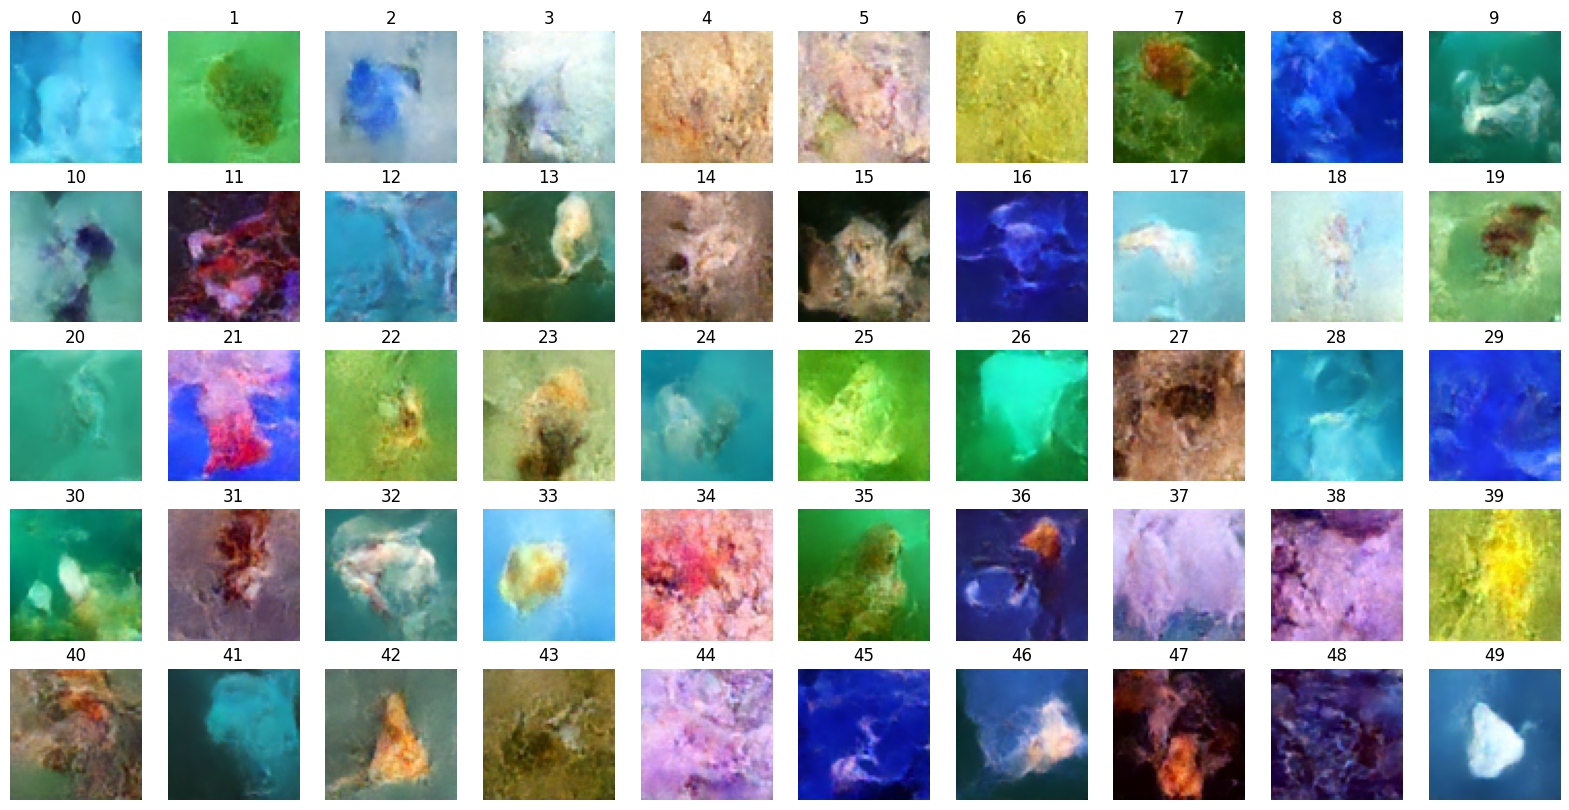

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axs = plt.subplots(5, 10, figsize=(20, 10))
for i, ax in enumerate(axs.flat):
    ax.imshow(Image.open(f"images/jellyfish_{i:02d}.png"))
    ax.set_title(i)
    ax.axis("off")
plt.show()

In [10]:
!zip -r images.zip images
from google.colab import files
files.download("images.zip")

  adding: images/ (stored 0%)
  adding: images/jellyfish_02.png (stored 0%)
  adding: images/jellyfish_29.png (stored 0%)
  adding: images/jellyfish_35.png (stored 0%)
  adding: images/jellyfish_13.png (stored 0%)
  adding: images/jellyfish_08.png (stored 0%)
  adding: images/jellyfish_23.png (stored 0%)
  adding: images/jellyfish_16.png (stored 0%)
  adding: images/jellyfish_38.png (stored 0%)
  adding: images/jellyfish_14.png (stored 0%)
  adding: images/jellyfish_37.png (stored 0%)
  adding: images/jellyfish_15.png (stored 0%)
  adding: images/jellyfish_22.png (stored 0%)
  adding: images/jellyfish_01.png (stored 0%)
  adding: images/jellyfish_36.png (stored 0%)
  adding: images/jellyfish_43.png (stored 0%)
  adding: images/jellyfish_24.png (stored 0%)
  adding: images/jellyfish_45.png (stored 0%)
  adding: images/jellyfish_32.png (stored 0%)
  adding: images/jellyfish_39.png (stored 0%)
  adding: images/jellyfish_31.png (stored 0%)
  adding: images/jellyfish_11.png (stored 0%)
  ad

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>